<a href="https://colab.research.google.com/github/dhiyasalmas/openmc/blob/main/OpenMC_Installation_in_Collab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Cara Running Pertama
###1. Jalankan Environment Setup
###2. Jalankan Drive OpenMC Build
###3. Jalankan Download Library
###4. Jalankan Drive Setup
###5. Buat Folder Baru
###6. Dalam Folder Baru, berikan shortcut openmc/openmc
###7. Dari sini, sudah dapat membuat xml untuk running OpenMC, Jangan lupa %cd di kode baru
###8. Setelah xml terbuat openmc dapat dijalankan dengan sekedar !openmc
-----------------------------------------------------------------------------
#Running Berikutnya
#####Dapat dilakukan dengan melakukan langkah 1 > 4 > 7 > 8

In [ ]:
!cat /proc/cpuinfo
print("---------------------------------------------------------------------------------------------------------------------------------------------")
!free -m


processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 79
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
stepping	: 0
microcode	: 0xffffffff
cpu MHz		: 2199.998
cache size	: 56320 KB
physical id	: 0
siblings	: 2
core id		: 0
cpu cores	: 1
apicid		: 0
initial apicid	: 0
fpu		: yes
fpu_exception	: yes
cpuid level	: 13
wp		: yes
flags		: fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch invpcid_single ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm rdseed adx smap xsaveopt arat md_clear arch_capabilities
bugs		: cpu_meltdown spectre_v1 spectre_v2 spec_store_bypass l1tf mds swapgs taa mmio_stale_data retbleed
bogomips	: 4399.99
clflush size	: 64
cache_alignment	: 64
addres

In [ ]:
#@title Environment Setup

from pathlib import Path

OPTIONS = {}

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
UPDATE_OPENMC = False # @param {type:"boolean"}
WORKSPACE = 'openmc'
OPTIONS['USE_GOOGLE_DRIVE'] = USE_GOOGLE_DRIVE

if OPTIONS['USE_GOOGLE_DRIVE']:
    !echo "Mounting Google Drive..."
    %cd /

    from google.colab import drive
    drive.mount('/content/drive')

    WORKSPACE = "/content/drive/MyDrive/openmc"
    %cd /content/drive/MyDrive

![ ! -d $WORKSPACE ] && echo -= Initial setup =- && git clone https://github.com/openmc-dev/openmc.git
%cd /content/drive/MyDrive

# will setup our conda package installation path as ‘/usr/local/lib/python3.6/site-packages/’.
import sys
sys.path.append('/usr/local/lib/python3.6/site-packages/')


Mounting Google Drive...
/
Mounted at /content/drive
/content/drive/MyDrive
/content/drive/MyDrive


In [ ]:
#@title Conda Install & Setup

! wget -c https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
! chmod +x Miniconda3-latest-Linux-x86_64.sh
! bash Miniconda3-latest-Linux-x86_64.sh -b -f -p /usr/local/

%cd /content/drive/MyDrive
! conda config --add channels conda-forge
! conda create -n openmc -y
! conda init
! conda shell.bash activate openmc
! conda install mamba -y
! mamba search openmc
! mamba install openmc -y

In [ ]:
#@title Drive OpenMC Build

%cd /content/drive/MyDrive/openmc
!mkdir build
%cd build
!cmake ..
!make -j
!make install


[Errno 2] No such file or directory: '/content/drive/MyDrive/openmc'
/content/build
/content/build/build
CMake Warning:
  Ignoring extra path from command line:

   ".."


CMake Error: The source directory "/content/build" does not appear to contain CMakeLists.txt.
Specify --help for usage, or press the help button on the CMake GUI.
make: *** No targets specified and no makefile found.  Stop.
make: *** No rule to make target 'install'.  Stop.


In [ ]:
#@title Drive Setup

import os
%cd /content/drive/MyDrive
! chmod -R 755 openmc/build/bin
pat = ':/content/drive/MyDrive/openmc/build/bin'
PATHS = os.environ['PATH']
if not pat in PATHS :
  os.environ['PATH'] += pat
! pip install uncertainties ipython
! sudo ldconfig /content/drive/MyDrive/openmc/openmc/lib/
os.environ['OPENMC_CROSS_SECTIONS'] = "/content/drive/MyDrive/endfb-vii.1-hdf5/cross_sections.xml"

/content/drive/MyDrive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.4/98.4 kB 998.3 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 9.1 MB/s eta 0:00:00
/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc.so.2 is not a symbolic link



In [ ]:
#@title Download Library
%cd /content/drive/MyDrive

!wget -c https://anl.box.com/shared/static/9igk353zpy8fn9ttvtrqgzvw1vtejoz6.xz -O ./endfb71.tar.xz

print ("Extracting files")
!tar -xvf endfb71.tar.xz

In [ ]:
#@title Running Build File

# ! source activate openmc && python openmc/examples/pincell_depletion/run_depletion.py
# ! source activate openmc && openmc
# ! python openmc/examples/lattice/simple/build_xml.py
# ! python openmc/examples/pincell/build_xml.py
%cd /content/drive/MyDrive/SFR/
! openmc

/content/drive/MyDrive/SFR
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
           

In [ ]:
#@title SFR Results
#  =======================>     TIMING STATISTICS     <=======================

#  Total time for initialization     = 8.9005e+00 seconds
#    Reading cross sections          = 5.4659e+00 seconds
#  Total time in simulation          = 1.1690e+03 seconds
#    Time in transport only          = 1.1684e+03 seconds
#    Time in inactive batches        = 1.0675e+02 seconds
#    Time in active batches          = 1.0622e+03 seconds
#    Time synchronizing fission bank = 1.4082e-01 seconds
#      Sampling source sites         = 1.2002e-01 seconds
#      SEND/RECV source sites        = 2.0632e-02 seconds
#    Time accumulating tallies       = 8.9369e-05 seconds
#    Time writing statepoints        = 2.8947e-01 seconds
#  Total time for finalization       = 5.7570e-06 seconds
#  Total time elapsed                = 1.1784e+03 seconds
#  Calculation Rate (inactive)       = 936.795 particles/second
#  Calculation Rate (active)         = 941.413 particles/second

#  ============================>     RESULTS     <============================

#  k-effective (Collision)     = 1.02623 +/- 0.00078
#  k-effective (Track-length)  = 1.02540 +/- 0.00082
#  k-effective (Absorption)    = 1.02484 +/- 0.00121
#  Combined k-effective        = 1.02560 +/- 0.00064
#  Leakage Fraction            = 0.02989 +/- 0.00016

# =======================>     TIMING STATISTICS     <=======================

#  Total time for initialization     = 4.0786e+01 seconds
#    Reading cross sections          = 3.3779e+01 seconds
#  Total time in simulation          = 2.5670e+03 seconds
#    Time in transport only          = 2.5665e+03 seconds
#    Time in inactive batches        = 5.1671e+02 seconds
#    Time in active batches          = 2.0503e+03 seconds
#    Time synchronizing fission bank = 3.3198e-01 seconds
#      Sampling source sites         = 2.8504e-01 seconds
#      SEND/RECV source sites        = 4.6602e-02 seconds
#    Time accumulating tallies       = 1.7973e-04 seconds
#    Time writing statepoints        = 3.9111e-02 seconds
#  Total time for finalization       = 1.6874e-05 seconds
#  Total time elapsed                = 2.6083e+03 seconds
#  Calculation Rate (inactive)       = 967.652 particles/second
#  Calculation Rate (active)         = 975.459 particles/second

#  ============================>     RESULTS     <============================

#  k-effective (Collision)     = 1.02573 +/- 0.00059
#  k-effective (Track-length)  = 1.02576 +/- 0.00061
#  k-effective (Absorption)    = 1.02493 +/- 0.00087
#  Combined k-effective        = 1.02548 +/- 0.00046
#  Leakage Fraction            = 0.02970 +/- 0.00012

#  =======================>     TIMING STATISTICS     <=======================

#  Total time for initialization     = 7.1613e+00 seconds
#    Reading cross sections          = 4.3407e+00 seconds
#  Total time in simulation          = 2.5625e+04 seconds
#    Time in transport only          = 2.5619e+04 seconds
#    Time in inactive batches        = 5.1243e+03 seconds
#    Time in active batches          = 2.0500e+04 seconds
#    Time synchronizing fission bank = 4.2870e+00 seconds
#      Sampling source sites         = 3.5142e+00 seconds
#      SEND/RECV source sites        = 7.7213e-01 seconds
#    Time accumulating tallies       = 2.5874e-04 seconds
#    Time writing statepoints        = 5.6190e-02 seconds
#  Total time for finalization       = 5.5740e-05 seconds
#  Total time elapsed                = 2.5642e+04 seconds
#  Calculation Rate (inactive)       = 975.743 particles/second
#  Calculation Rate (active)         = 975.6 particles/second

#  ============================>     RESULTS     <============================

#  k-effective (Collision)     = 1.02560 +/- 0.00020
#  k-effective (Track-length)  = 1.02554 +/- 0.00020
#  k-effective (Absorption)    = 1.02580 +/- 0.00029
#  Combined k-effective        = 1.02564 +/- 0.00015
#  Leakage Fraction            = 0.02981 +/- 0.00004

In [ ]:
#@title SFR Material

%cd /content/drive/MyDrive/SFR/
import openmc
import openmc.model
import openmc.stats
import openmc.deplete

m_low = openmc.Material(name="lower-structure")
m_low.add_nuclide("Na23", 1.5591e-2, "ao")
m_low.add_nuclide("Fe56", 1.5878e-2, "ao")
m_low.add_nuclide("Ni59", 3.2604e-3, "ao")
m_low.add_nuclide("Cr52", 3.2355e-3, "ao")
m_low.add_nuclide("Mn55", 5.0846e-4, "ao")
m_low.add_nuclide("Mo96", 4.3524e-4, "ao")
m_low.set_density('sum')

m_coolant = openmc.Material(name="coolant")
m_coolant.add_nuclide("Na23", 2.2272e-2, "ao")
m_coolant.set_density('sum')

m_HT9 = openmc.Material(name="HT-9")
m_HT9.add_nuclide("Fe56", 6.9715e-2, "ao")
m_HT9.add_nuclide("Ni59", 4.2984e-4, "ao")
m_HT9.add_nuclide("Cr52", 1.0366e-2, "ao")
m_HT9.add_nuclide("Mn55", 4.5921e-4, "ao")
m_HT9.add_nuclide("Mo96", 4.9007e-4, "ao")
m_HT9.set_density('sum')

m_B4C = openmc.Material(name="Natural-B4C")
m_B4C.add_element("C", 1.9657e-2, "ao")
m_B4C.add_nuclide("B10", 1.5018e-2, "ao")
m_B4C.add_nuclide("B11", 6.3609e-2, "ao")
m_B4C.set_density('sum')

m_B4C_e = openmc.Material(name="Enriched-B4C")
m_B4C_e.add_element("C", 2.0632e-2, "ao")
m_B4C_e.add_nuclide("B10", 5.3642e-2, "ao")
m_B4C_e.add_nuclide("B11", 2.8884e-2, "ao")
m_B4C_e.set_density('sum')

m_Plenum = openmc.Material(name="Gas-Plenum")
m_Plenum.add_nuclide("He4", 2.68714e-5, "ao")
m_Plenum.set_density('sum')

# Inner Core up to 17.16
m_IC11 = openmc.Material(name="IC-11")
m_IC11.add_nuclide("U234", 1.1369e-6, "ao")
m_IC11.add_nuclide("U235", 3.0421e-5, "ao")
m_IC11.add_nuclide("U236", 2.4896e-6, "ao")
m_IC11.add_nuclide("U238", 1.9613e-2, "ao")

m_IC11.add_nuclide("Np237", 4.6686e-5, "ao")
m_IC11.add_nuclide("Pu236", 4.9700e-10, "ao")
m_IC11.add_nuclide("Pu238", 1.1695e-4, "ao")
m_IC11.add_nuclide("Pu239", 2.2076e-3, "ao")
m_IC11.add_nuclide("Pu240", 1.3244e-3, "ao")
m_IC11.add_nuclide("Pu241", 1.9375e-4, "ao")
m_IC11.add_nuclide("Pu242", 2.9277e-4, "ao")
m_IC11.add_nuclide("Am241", 1.0791e-4, "ao")
m_IC11.add_nuclide("Am242_m1", 9.2989e-6, "ao")
m_IC11.add_nuclide("Am243", 1.0017e-4, "ao")
m_IC11.add_nuclide("Cm242", 5.6250e-6, "ao")
m_IC11.add_nuclide("Cm243", 5.4321e-7, "ao")
m_IC11.add_nuclide("Cm244", 6.7240e-5, "ao")
m_IC11.add_nuclide("Cm245", 1.7397e-5, "ao")
m_IC11.add_nuclide("Cm246", 9.2285e-6, "ao")
m_IC11.add_nuclide("Zr91", 7.2802e-3, "ao")
m_IC11.add_nuclide("Mo96", 9.2873e-4, "ao")
m_IC11.volume = 5.646578945
m_IC11.depletable = True
m_IC11.set_density('sum')

# Inner Core 17.16 to 34.33
m_IC12 = openmc.Material(name="IC-12")
m_IC12.add_nuclide("U234", 1.0856e-6, "ao")
m_IC12.add_nuclide("U235", 2.9338e-5, "ao")
m_IC12.add_nuclide("U236", 2.5117e-6, "ao")
m_IC12.add_nuclide("U238", 1.9474e-2, "ao")

m_IC12.add_nuclide("Np237", 4.6962e-5, "ao")
m_IC12.add_nuclide("Pu236", 5.5883e-10, "ao")
m_IC12.add_nuclide("Pu238", 1.1284e-4, "ao")
m_IC12.add_nuclide("Pu239", 2.1814e-3, "ao")
m_IC12.add_nuclide("Pu240", 1.2955e-3, "ao")
m_IC12.add_nuclide("Pu241", 1.8610e-4, "ao")
m_IC12.add_nuclide("Pu242", 2.8911e-4, "ao")
m_IC12.add_nuclide("Am241", 1.0465e-4, "ao")
m_IC12.add_nuclide("Am242_m1", 9.0848e-6, "ao")
m_IC12.add_nuclide("Am243", 9.8324e-5, "ao")
m_IC12.add_nuclide("Cm242", 5.8208e-6, "ao")
m_IC12.add_nuclide("Cm243", 5.0246e-7, "ao")
m_IC12.add_nuclide("Cm244", 6.5722e-5, "ao")
m_IC12.add_nuclide("Cm245", 1.6743e-5, "ao")
m_IC12.add_nuclide("Cm246", 9.1426e-6, "ao")
m_IC12.add_nuclide("Zr91", 7.2802e-3, "ao")
m_IC12.add_nuclide("Mo96", 1.1464e-3, "ao")
m_IC12.volume = 5.646578945
m_IC12.depletable = True
m_IC12.set_density('sum')

# Inner Core 34.33 to 51.49
m_IC13 = openmc.Material(name="IC-13")
m_IC13.add_nuclide("U234", 1.0727e-6, "ao")
m_IC13.add_nuclide("U235", 2.8961e-5, "ao")
m_IC13.add_nuclide("U236", 2.5536e-6, "ao")
m_IC13.add_nuclide("U238", 1.9433e-2, "ao")

m_IC13.add_nuclide("Np237", 4.6782e-5, "ao")
m_IC13.add_nuclide("Pu236", 5.6701e-10, "ao")
m_IC13.add_nuclide("Pu238", 1.1196e-4, "ao")
m_IC13.add_nuclide("Pu239", 2.1754e-3, "ao")
m_IC13.add_nuclide("Pu240", 1.2902e-3, "ao")
m_IC13.add_nuclide("Pu241", 1.8518e-4, "ao")
m_IC13.add_nuclide("Pu242", 2.8818e-4, "ao")
m_IC13.add_nuclide("Am241", 1.0353e-4, "ao")
m_IC13.add_nuclide("Am242_m1", 9.0224e-6, "ao")
m_IC13.add_nuclide("Am243", 9.7993e-5, "ao")
m_IC13.add_nuclide("Cm242", 5.9476e-6, "ao")
m_IC13.add_nuclide("Cm243", 5.0136e-7, "ao")
m_IC13.add_nuclide("Cm244", 6.5622e-5, "ao")
m_IC13.add_nuclide("Cm245", 1.6663e-5, "ao")
m_IC13.add_nuclide("Cm246", 9.1307e-6, "ao")
m_IC13.add_nuclide("Zr91", 7.2802e-3, "ao")
m_IC13.add_nuclide("Mo96", 1.2031e-3, "ao")
m_IC13.volume = 5.646578945
m_IC13.depletable = True
m_IC13.set_density('sum')

# Inner Core 51.49 to 68.66
m_IC14 = openmc.Material(name="IC-14")
m_IC14.add_nuclide("U234", 1.1028e-6, "ao")
m_IC14.add_nuclide("U235", 3.0070e-5, "ao")
m_IC14.add_nuclide("U236", 2.3779e-6, "ao")
m_IC14.add_nuclide("U238", 1.9550e-2, "ao")

m_IC14.add_nuclide("Np237", 4.7603e-5, "ao")
m_IC14.add_nuclide("Pu236", 5.5075e-10, "ao")
m_IC14.add_nuclide("Pu238", 1.1370e-4, "ao")
m_IC14.add_nuclide("Pu239", 2.1813e-3, "ao")
m_IC14.add_nuclide("Pu240", 1.2986e-3, "ao")
m_IC14.add_nuclide("Pu241", 1.8537e-4, "ao")
m_IC14.add_nuclide("Pu242", 2.9038e-4, "ao")
m_IC14.add_nuclide("Am241", 1.0686e-4, "ao")
m_IC14.add_nuclide("Am242_m1", 9.1756e-6, "ao")
m_IC14.add_nuclide("Am243", 9.8630e-5, "ao")
m_IC14.add_nuclide("Cm242", 5.4901e-6, "ao")
m_IC14.add_nuclide("Cm243", 4.8876e-7, "ao")
m_IC14.add_nuclide("Cm244", 6.5349e-5, "ao")
m_IC14.add_nuclide("Cm245", 1.6696e-5, "ao")
m_IC14.add_nuclide("Cm246", 9.1364e-6, "ao")
m_IC14.add_nuclide("Zr91", 7.2802e-3, "ao")
m_IC14.add_nuclide("Mo96", 1.0625e-3, "ao")
m_IC14.volume = 5.646578945
m_IC14.depletable = True
m_IC14.set_density('sum')

# Inner Core 68.66 to 85.82
m_IC15 = openmc.Material(name="IC-15")
m_IC15.add_nuclide("U234", 1.1759e-6, "ao")
m_IC15.add_nuclide("U235", 3.2571e-5, "ao")
m_IC15.add_nuclide("U236", 2.0226e-6, "ao")
m_IC15.add_nuclide("U238", 1.9801e-2, "ao")

m_IC15.add_nuclide("Np237", 4.8895e-5, "ao")
m_IC15.add_nuclide("Pu236", 4.8775e-10, "ao")
m_IC15.add_nuclide("Pu238", 1.1829e-4, "ao")
m_IC15.add_nuclide("Pu239", 2.2011e-3, "ao")
m_IC15.add_nuclide("Pu240", 1.3248e-3, "ao")
m_IC15.add_nuclide("Pu241", 1.8845e-4, "ao")
m_IC15.add_nuclide("Pu242", 2.9569e-4, "ao")
m_IC15.add_nuclide("Am241", 1.1421e-4, "ao")
m_IC15.add_nuclide("Am242_m1", 9.4890e-6, "ao")
m_IC15.add_nuclide("Am243", 1.0032e-4, "ao")
m_IC15.add_nuclide("Cm242", 4.5416e-6, "ao")
m_IC15.add_nuclide("Cm243", 4.8480e-7, "ao")
m_IC15.add_nuclide("Cm244", 6.5394e-5, "ao")
m_IC15.add_nuclide("Cm245", 1.7026e-5, "ao")
m_IC15.add_nuclide("Cm246", 9.1805e-6, "ao")
m_IC15.add_nuclide("Zr91", 7.2802e-3, "ao")
m_IC15.add_nuclide("Mo96", 7.4065e-4, "ao")
m_IC15.volume = 5.646578945
m_IC15.depletable = True
m_IC15.set_density('sum')

# Outer Core up to 17.16
m_IC21 = openmc.Material(name="IC-21")
m_IC21.add_nuclide("U234", 1.6317e-6, "ao")
m_IC21.add_nuclide("U235", 3.0822e-5, "ao")
m_IC21.add_nuclide("U236", 1.7881e-6, "ao")
m_IC21.add_nuclide("U238", 1.8244e-2, "ao")

m_IC21.add_nuclide("Np237", 9.8244e-5, "ao")
m_IC21.add_nuclide("Pu236", 7.1175e-10, "ao")
m_IC21.add_nuclide("Pu238", 1.6436e-4, "ao")
m_IC21.add_nuclide("Pu239", 2.8147e-3, "ao")
m_IC21.add_nuclide("Pu240", 1.7467e-3, "ao")
m_IC21.add_nuclide("Pu241", 2.8976e-4, "ao")
m_IC21.add_nuclide("Pu242", 4.0754e-4, "ao")
m_IC21.add_nuclide("Am241", 1.8607e-4, "ao")
m_IC21.add_nuclide("Am242_m1", 1.2185e-5, "ao")
m_IC21.add_nuclide("Am243", 1.3234e-4, "ao")
m_IC21.add_nuclide("Cm242", 6.4688e-6, "ao")
m_IC21.add_nuclide("Cm243", 6.3471e-7, "ao")
m_IC21.add_nuclide("Cm244", 8.0107e-5, "ao")
m_IC21.add_nuclide("Cm245", 2.0200e-5, "ao")
m_IC21.add_nuclide("Cm246", 1.0443e-5, "ao")
m_IC21.add_nuclide("Zr91", 7.2802e-3, "ao")
m_IC21.add_nuclide("Mo96", 8.1524e-4, "ao")
m_IC21.volume = 5.646578945
m_IC21.depletable = True
m_IC21.set_density('sum')

# Outer Core 17.16 to 34.33
m_IC22 = openmc.Material(name="IC-22")
m_IC22.add_nuclide("U234", 1.5766e-6, "ao")
m_IC22.add_nuclide("U235", 2.9870e-5, "ao")
m_IC22.add_nuclide("U236", 1.8534e-6, "ao")
m_IC22.add_nuclide("U238", 1.8144e-2, "ao")

m_IC22.add_nuclide("Np237", 9.7300e-5, "ao")
m_IC22.add_nuclide("Pu236", 8.2505e-10, "ao")
m_IC22.add_nuclide("Pu238", 1.6026e-4, "ao")
m_IC22.add_nuclide("Pu239", 2.7664e-3, "ao")
m_IC22.add_nuclide("Pu240", 1.7191e-3, "ao")
m_IC22.add_nuclide("Pu241", 2.8138e-4, "ao")
m_IC22.add_nuclide("Pu242", 4.0412e-4, "ao")
m_IC22.add_nuclide("Am241", 1.8127e-4, "ao")
m_IC22.add_nuclide("Am242_m1", 1.2045e-5, "ao")
m_IC22.add_nuclide("Am243", 1.3019e-4, "ao")
m_IC22.add_nuclide("Cm242", 6.8630e-6, "ao")
m_IC22.add_nuclide("Cm243", 6.0893e-7, "ao")
m_IC22.add_nuclide("Cm244", 7.8889e-5, "ao")
m_IC22.add_nuclide("Cm245", 1.9678e-5, "ao")
m_IC22.add_nuclide("Cm246", 1.0371e-5, "ao")
m_IC22.add_nuclide("Zr91", 7.2802e-3, "ao")
m_IC22.add_nuclide("Mo96", 1.0174e-3, "ao")
m_IC22.volume = 5.646578945
m_IC22.depletable = True
m_IC22.set_density('sum')

# Outer Core 34.33 to 51.49
m_IC23 = openmc.Material(name="IC-23")
m_IC23.add_nuclide("U234", 1.5638e-6, "ao")
m_IC23.add_nuclide("U235", 2.9561e-5, "ao")
m_IC23.add_nuclide("U236", 1.8941e-6, "ao")
m_IC23.add_nuclide("U238", 1.8115e-2, "ao")

m_IC23.add_nuclide("Np237", 9.6775e-5, "ao")
m_IC23.add_nuclide("Pu236", 8.4282e-10, "ao")
m_IC23.add_nuclide("Pu238", 1.5949e-4, "ao")
m_IC23.add_nuclide("Pu239", 2.7538e-3, "ao")
m_IC23.add_nuclide("Pu240", 1.7135e-3, "ao")
m_IC23.add_nuclide("Pu241", 2.8012e-4, "ao")
m_IC23.add_nuclide("Pu242", 4.0321e-4, "ao")
m_IC23.add_nuclide("Am241", 1.7970e-4, "ao")
m_IC23.add_nuclide("Am242_m1", 1.2021e-5, "ao")
m_IC23.add_nuclide("Am243", 1.2985e-4, "ao")
m_IC23.add_nuclide("Cm242", 7.0553e-6, "ao")
m_IC23.add_nuclide("Cm243", 6.0901e-7, "ao")
m_IC23.add_nuclide("Cm244", 7.8847e-5, "ao")
m_IC23.add_nuclide("Cm245", 1.9613e-5, "ao")
m_IC23.add_nuclide("Cm246", 1.0361e-5, "ao")
m_IC23.add_nuclide("Zr91", 7.2802e-3, "ao")
m_IC23.add_nuclide("Mo96", 1.0697e-3, "ao")
m_IC23.volume = 5.646578945
m_IC23.depletable = True
m_IC23.set_density('sum')

# Outer Core 51.49 to 68.66
m_IC24 = openmc.Material(name="IC-24")
m_IC24.add_nuclide("U234", 1.5894e-6, "ao")
m_IC24.add_nuclide("U235", 3.0391e-5, "ao")
m_IC24.add_nuclide("U236", 1.7528e-6, "ao")
m_IC24.add_nuclide("U238", 1.8191e-2, "ao")

m_IC24.add_nuclide("Np237", 9.8481e-5, "ao")
m_IC24.add_nuclide("Pu236", 8.0703e-10, "ao")
m_IC24.add_nuclide("Pu238", 1.6063e-4, "ao")
m_IC24.add_nuclide("Pu239", 2.7786e-3, "ao")
m_IC24.add_nuclide("Pu240", 1.7231e-3, "ao")
m_IC24.add_nuclide("Pu241", 2.8135e-4, "ao")
m_IC24.add_nuclide("Pu242", 4.0530e-4, "ao")
m_IC24.add_nuclide("Am241", 1.8397e-4, "ao")
m_IC24.add_nuclide("Am242_m1", 1.2039e-5, "ao")
m_IC24.add_nuclide("Am243", 1.3036e-4, "ao")
m_IC24.add_nuclide("Cm242", 6.4446e-6, "ao")
m_IC24.add_nuclide("Cm243", 5.9753e-7, "ao")
m_IC24.add_nuclide("Cm244", 7.8479e-5, "ao")
m_IC24.add_nuclide("Cm245", 1.9635e-5, "ao")
m_IC24.add_nuclide("Cm246", 1.0367e-5, "ao")
m_IC24.add_nuclide("Zr91", 7.2802e-3, "ao")
m_IC24.add_nuclide("Mo96", 9.4870e-4, "ao")
m_IC24.volume = 5.646578945
m_IC24.depletable = True
m_IC24.set_density('sum')

# Outer Core 68.66 to 85.82
m_IC25 = openmc.Material(name="IC-25")
m_IC25.add_nuclide("U234", 1.6552e-6, "ao")
m_IC25.add_nuclide("U235", 3.2250e-5, "ao")
m_IC25.add_nuclide("U236", 1.4710e-6, "ao")
m_IC25.add_nuclide("U238", 1.8359e-2, "ao")

m_IC25.add_nuclide("Np237", 1.0175e-4, "ao")
m_IC25.add_nuclide("Pu236", 6.8053e-10, "ao")
m_IC25.add_nuclide("Pu238", 1.6416e-4, "ao")
m_IC25.add_nuclide("Pu239", 2.8416e-3, "ao")
m_IC25.add_nuclide("Pu240", 1.7508e-3, "ao")
m_IC25.add_nuclide("Pu241", 2.8697e-4, "ao")
m_IC25.add_nuclide("Pu242", 4.1028e-4, "ao")
m_IC25.add_nuclide("Am241", 1.9339e-4, "ao")
m_IC25.add_nuclide("Am242_m1", 1.2064e-5, "ao")
m_IC25.add_nuclide("Am243", 1.3206e-4, "ao")
m_IC25.add_nuclide("Cm242", 5.1976e-6, "ao")
m_IC25.add_nuclide("Cm243", 5.9372e-7, "ao")
m_IC25.add_nuclide("Cm244", 7.8359e-5, "ao")
m_IC25.add_nuclide("Cm245", 1.9913e-5, "ao")
m_IC25.add_nuclide("Cm246", 1.0410e-5, "ao")
m_IC25.add_nuclide("Zr91", 7.2802e-3, "ao")
m_IC25.add_nuclide("Mo96", 6.6172e-4, "ao")
m_IC25.volume = 5.646578945
m_IC25.depletable = True
m_IC25.set_density('sum')



/content/drive/MyDrive/SFR


In [ ]:
#@title SFR Geometry
###============================================== ###
###=================== Geometry ================= ###
###============================================== ###

all_coolant_cell = openmc.Cell(fill=m_coolant)
outer_univ = openmc.Universe(cells=(all_coolant_cell,))

# Rangka Hexagonal Luar FA + Duct
fa1 = openmc.model.HexagonalPrism(8.67128, 'x')
duct1 = openmc.model.HexagonalPrism(9.12923, 'x')
out1 = openmc.model.HexagonalPrism(9.38026, 'x')

# Driver Subassembly
ds_cylinder1 = openmc.ZCylinder(r=0.32360)
ds_cylinder2 = openmc.ZCylinder(r=0.38567)
# ds_hex = openmc.model.HexagonalPrism(0.517652, 'y')
ds_ls = openmc.ZPlane(35.76)
ds_lr = openmc.ZPlane(160.92)
ac1 = openmc.ZPlane(178.084)
ac2 = openmc.ZPlane(195.248)
ac3 = openmc.ZPlane(212.412)
ac4 = openmc.ZPlane(229.576)
ac5 = openmc.ZPlane(246.74)
ds_rs = openmc.ZPlane(266.8)
ds_gp = openmc.ZPlane(367.81)
ds_us = openmc.ZPlane(480.2, boundary_type='vacuum')
bottom = openmc.ZPlane(0, boundary_type='vacuum')

ic_lower_structure = openmc.Cell(name='Lower-Structure', fill=m_low,
                              region=-ds_cylinder2 & +bottom & -ds_ls)
ic_lower_reflector = openmc.Cell(name='Lower-Reflector', fill=m_HT9,
                              region=-ds_cylinder2 & +ds_ls & -ds_lr)
ic_bond_sodium = openmc.Cell(name='Bond-Sodium', fill=m_coolant,
                          region=-ds_cylinder1 & +ac5 & -ds_rs)
ic_clad_ds = openmc.Cell(name='Clad-IC', fill=m_HT9,
                      region=+ds_cylinder1 & -ds_cylinder2 & +bottom & -ds_gp)
ic_gas_plenum = openmc.Cell(name='Gas-Plenum', fill=m_Plenum,
                         region=-ds_cylinder1 & +ds_rs & -ds_gp)
ic_upper_reflector = openmc.Cell(name='Upper-Reflector', fill=m_HT9,
                              region=-ds_cylinder2 & +ds_gp & -ds_us)
inner1 = openmc.Cell(name='Inner-1', fill=m_IC11,
                     region=-ds_cylinder1 & +ds_lr & -ac1)
inner2 = openmc.Cell(name='Inner-2', fill=m_IC12,
                     region=-ds_cylinder1 & +ac1 & -ac2)
inner3 = openmc.Cell(name='Inner-3', fill=m_IC13,
                     region=-ds_cylinder1 & +ac2 & -ac3)
inner4 = openmc.Cell(name='Inner-4', fill=m_IC14,
                     region=-ds_cylinder1 & +ac3 & -ac4)
inner5 = openmc.Cell(name='Inner-5', fill=m_IC15,
                     region=-ds_cylinder1 & +ac4 & -ac5)
luar_ic = openmc.Cell(fill=m_coolant, region=(+ds_cylinder2 & +bottom & -ds_us) | (-bottom | +ds_us))
inner_core = openmc.Universe(name='Batang-IC',
                                     cells=(ic_lower_structure, ic_lower_reflector,
                                            ic_bond_sodium, ic_clad_ds, ic_gas_plenum,
                                            ic_upper_reflector, inner1, inner2,
                                            inner3, inner4, inner5, luar_ic))
ic_lattice = openmc.HexLattice(name='IC')
ic_lattice.center = (0., 0.)
ic_lattice.pitch = (0.8966,)
ic_lattice.outer = outer_univ
ic_lattice.orientation = 'x'
# 10 ring
ic_ring = [ [inner_core] ]
ic_ring += [i * 6 * [inner_core] for i in range(1,10)]
ic_ring.reverse()
ic_lattice.universes = ic_ring
ic_lattice_cell = openmc.Cell(fill=ic_lattice, region=+bottom & -ds_us & -fa1)
ic_duct = openmc.Cell(fill=m_HT9, region=+bottom & -ds_us & +fa1 & -duct1)
ic_duct_outer = openmc.Cell(fill=m_coolant, region=(-bottom | +ds_us) | (+duct1 & +bottom & -ds_us))
ic_universe = openmc.Universe(name='Inner-Cores', cells=(ic_lattice_cell, ic_duct, ic_duct_outer))


oc_lower_structure = openmc.Cell(name='Lower-Structure', fill=m_low,
                              region=-ds_cylinder2 & +bottom & -ds_ls)
oc_lower_reflector = openmc.Cell(name='Lower-Reflector', fill=m_HT9,
                              region=-ds_cylinder2 & +ds_ls & -ds_lr)
oc_bond_sodium = openmc.Cell(name='Bond-Sodium', fill=m_coolant,
                          region=-ds_cylinder1 & +ac5 & -ds_rs)
oc_clad_ds = openmc.Cell(name='Clad-IC', fill=m_HT9,
                      region=+ds_cylinder1 & -ds_cylinder2 & +bottom & -ds_gp)
oc_gas_plenum = openmc.Cell(name='Gas-Plenum', fill=m_Plenum,
                         region=-ds_cylinder1 & +ds_rs & -ds_gp)
oc_upper_reflector = openmc.Cell(name='Upper-Reflector', fill=m_HT9,
                              region=-ds_cylinder2 & +ds_gp & -ds_us)
outer1 = openmc.Cell(name='Outer-1', fill=m_IC21,
                     region=-ds_cylinder1 & +ds_lr & -ac1)
outer2 = openmc.Cell(name='Outer-2', fill=m_IC22,
                     region=-ds_cylinder1 & +ac1 & -ac2)
outer3 = openmc.Cell(name='Outer-3', fill=m_IC23,
                     region=-ds_cylinder1 & +ac2 & -ac3)
outer4 = openmc.Cell(name='Outer-4', fill=m_IC24,
                     region=-ds_cylinder1 & +ac3 & -ac4)
outer5 = openmc.Cell(name='Outer-5', fill=m_IC25,
                     region=-ds_cylinder1 & +ac4 & -ac5)
luar_oc = openmc.Cell(fill=m_coolant, region=(+ds_cylinder2 & +bottom & -ds_us) | (-bottom | +ds_us))
outer_core = openmc.Universe(name='Batang-OC',
                                     cells=(oc_lower_structure, oc_lower_reflector,
                                            oc_bond_sodium, oc_clad_ds, oc_gas_plenum,
                                            oc_upper_reflector, outer1, outer2,
                                            outer3, outer4, outer5, luar_oc))
oc_lattice = openmc.HexLattice(name='OC')
oc_lattice.center = (0., 0.)
oc_lattice.pitch = (0.8966,)
oc_lattice.outer = outer_univ
oc_lattice.orientation = 'x'
# 10 ring
oc_ring = [ [outer_core] ]
oc_ring += [i * 6 * [outer_core] for i in range(1,10)]
oc_ring.reverse()
oc_lattice.universes = oc_ring
oc_lattice_cell = openmc.Cell(fill=oc_lattice, region=+bottom & -ds_us & -fa1)
oc_duct = openmc.Cell(fill=m_HT9, region=+bottom & -ds_us & +fa1 & -duct1)
oc_duct_outer = openmc.Cell(fill=m_coolant, region=(-bottom | +ds_us) | (+duct1 & +bottom & -ds_us))
oc_universe = openmc.Universe(name='Outer-Cores', cells=(oc_lattice_cell, oc_duct, oc_duct_outer))

# Radial Reflector Subassembly
rrs_cylinder = openmc.ZCylinder(r=0.77565)
# rrs_hex = openmc.model.HexagonalPrism(0.896509, 'y')

rrs_ls = openmc.Cell(name="RRS-LS", fill=m_low,
                     region=-rrs_cylinder & +bottom & -ds_ls)
rrs_lr = openmc.Cell(name='RRS-LR', fill=m_HT9,
                     region=-rrs_cylinder & +ds_ls & -ds_lr)
rrs_rr = openmc.Cell(name='RRS-RR', fill=m_HT9,
                     region=-rrs_cylinder & +ds_lr & -ds_gp)
rrs_us = openmc.Cell(name='RRS-US', fill=m_HT9,
                     region=-rrs_cylinder & +ds_gp & -ds_us)
luar_rrs = openmc.Cell(fill=m_coolant, region=(+rrs_cylinder & +bottom & -ds_us) | (-bottom | +ds_us))
batang_rrs  = openmc.Universe(name='Batang-RRS',
                              cells=(rrs_ls, rrs_lr, rrs_rr,
                                     rrs_us, luar_rrs))

rrs_lattice = openmc.HexLattice(name='RRS')
rrs_lattice.center = (0.,0.)
rrs_lattice.pitch = (1.5528,)
rrs_lattice.outer = outer_univ
rrs_lattice.orientation = 'x'
# 6 ring
rrs_ring = [ [ batang_rrs ] ]
rrs_ring += [i * 6 * [batang_rrs] for i in range(1,6)]
rrs_ring.reverse()
rrs_lattice.universes = rrs_ring
rrs_lattice_cell = openmc.Cell(fill=rrs_lattice,
                               region=+bottom & -ds_us & -fa1)
rrs_duct = openmc.Cell(fill=m_HT9, region=+bottom & -ds_us & +fa1 & -duct1)
rrs_duct_outer = openmc.Cell(fill=m_coolant, region=(-bottom | +ds_us) | (+duct1 & +bottom & -ds_us))
rrs_universe = openmc.Universe(name='Radial-Reflectors',
                               cells=(rrs_lattice_cell, rrs_duct, rrs_duct_outer))


# Radial Shield Subassembly
rss_cylinder1 = openmc.ZCylinder(r=1.427745)
rss_cylinder2 = openmc.ZCylinder(r=1.679375)
# rss_hex = openmc.model.HexagonalPrism(1.94013, 'y')

rss_ls = openmc.Cell(name='RSS-LS', fill=m_low,
                     region=-rss_cylinder2 & +bottom & -ds_ls)
rss_lr = openmc.Cell(name='RSS-LR', fill=m_HT9,
                     region=-rss_cylinder2 & +ds_ls & -ds_lr)
rss_shield = openmc.Cell(name='RSS-Shield', fill=m_B4C,
                         region=-rss_cylinder1 & +ds_lr & -ds_gp)
rss_clad = openmc.Cell(name='RSS-Cladding', fill=m_HT9,
                       region=+rss_cylinder1 & -rss_cylinder2 & +ds_lr & -ds_gp)
rss_us = openmc.Cell(name='RSS-US', fill=m_HT9,
                     region=-rss_cylinder2 & +ds_gp & -ds_us)
luar_rss = openmc.Cell(fill=m_coolant, region=(+rss_cylinder2 & +bottom & -ds_us) | (-bottom | +ds_us))
batang_rss = openmc.Universe(name='Batang-RSS',
                             cells=(rss_ls, rss_lr, rss_shield,
                                    rss_clad, rss_us, luar_rss))

rss_lattice = openmc.HexLattice(name='RSS')
rss_lattice.center = (0.,0.)
rss_lattice.pitch = (3.3604,)
rss_lattice.outer = outer_univ
rss_lattice.orientation = 'x'
# 3 Ring
rss_ring = [ [ batang_rss ] ]
rss_ring += [i * 6 * [batang_rss] for i in range(1,3)]
rss_ring.reverse()
rss_lattice.universes = rss_ring
rss_lattice_cell = openmc.Cell(fill=rss_lattice,
                               region=+bottom & -ds_us & -fa1)
rss_duct = openmc.Cell(fill=m_HT9, region=+bottom & -ds_us & +fa1 & -duct1)
rss_duct_outer = openmc.Cell(fill=m_coolant, region=(-bottom | +ds_us) | (+duct1 & +bottom & -ds_us))
rss_universe = openmc.Universe(name='Radial-Shields',
                               cells=(rss_lattice_cell, rss_duct, rss_duct_outer))



# Control Subassembly
cs_cylinder1 = openmc.ZCylinder(r=2.289005)
cs_cylinder2 = openmc.ZCylinder(r=2.36063)
cs_hexy = openmc.model.HexagonalPrism(2.80465, 'y')
cs_hexx1 = openmc.model.HexagonalPrism(7.7485, 'x')
cs_hexx2 = openmc.model.HexagonalPrism(8.20645, 'x')
cs_top = openmc.ZPlane(333.49)

cs_ls = openmc.Cell(name='CS-LS',fill=m_low,
                    region=-cs_cylinder2 & +bottom & -ds_ls)
cs_lr = openmc.Cell(name='CS-LR', fill=m_HT9,
                    region=-cs_cylinder2 & +ds_ls & -ds_lr)
cs_edb = openmc.Cell(name='CS-EDB', fill=m_coolant,
                     region=-cs_cylinder1 & +ds_lr & -ac5)
cs_cedb = openmc.Cell(name='CS-CEDB', fill=m_HT9,
                      region=+cs_cylinder1 & -cs_cylinder2 & +ds_lr & -ac5)
cs_ca = openmc.Cell(name='CS-CA', fill=m_B4C_e,
                    region=-cs_cylinder1 & +ac5 & -cs_top)
cs_cca = openmc.Cell(name='CS-CCA', fill=m_HT9,
                     region=+cs_cylinder1 & -cs_cylinder2 & +ac5 & -cs_top)
cs_edt = openmc.Cell(name='CS-EDT', fill=m_coolant,
                     region=-cs_cylinder1 & +cs_top & -ds_us)
cs_cedt = openmc.Cell(name='CS-CEDT', fill=m_HT9,
                      region=+cs_cylinder1 & -cs_cylinder2 & +cs_top & -ds_us)
luar_cs = openmc.Cell(fill=m_coolant,
                     region=(+cs_cylinder2 & +bottom & -ds_us) | (-bottom | +ds_us))
batang_cs = openmc.Universe(name='Batang-CS',
                            cells=(cs_ls, cs_lr, cs_edb, cs_cedb,
                                   cs_ca, cs_cca, cs_edt, cs_cedt,
                                   luar_cs))

cs_lattice = openmc.HexLattice(name='CS')
cs_lattice.center = (0.,0.)
cs_lattice.pitch = (4.8578,)
cs_lattice.outer = outer_univ
cs_lattice.orientation = 'x'
# 2 Ring
cs_lattice.universes = [
    [batang_cs]*6,
    [batang_cs]
]
cs_lattice_cell = openmc.Cell(fill=cs_lattice,
                              region=+bottom & -ds_us & -cs_hexx1)
cs_c1 = openmc.Cell(fill=m_HT9,
                    region=+bottom & -ds_us & +cs_hexx1 & -cs_hexx2)
cs_m1 = openmc.Cell(fill=m_coolant,
                    region=+bottom & -ds_us & +cs_hexx2 & -fa1)
cs_c2 = openmc.Cell(fill=m_HT9,
                    region=+bottom & -ds_us & +fa1 & -duct1)
cs_m2 = openmc.Cell(fill=m_coolant,
                    region=+bottom & -ds_us & +duct1)
cs_universe = openmc.Universe(name='Controls',
                              cells=(cs_lattice_cell,
                                     cs_c1, cs_c2,
                                     cs_m1, cs_m2))



# Core Layout
# cl_hex = openmc.model.HexagonalPrism(347.0329/2, 'y')
cl_topy = openmc.YPlane(178.7181, boundary_type='vacuum')
cl_bottomy = openmc.YPlane(-178.7181, boundary_type='vacuum')
cl_topx = openmc.XPlane(168.848161, boundary_type='vacuum')
cl_bottomx = openmc.XPlane(-168.8448161, boundary_type='vacuum')
cl_1 = openmc.Plane(1, 1.73205, 0, 347.0329, boundary_type='vacuum')
cl_2 = openmc.Plane(1, 1.73205, 0, -347.0329, boundary_type='vacuum')
cl_3 = openmc.Plane(-1, 1.73205, 0, 347.0329, boundary_type='vacuum')
cl_4 = openmc.Plane(-1, 1.73205, 0, -347.0329, boundary_type='vacuum')

cl_lattice = openmc.HexLattice()
cl_lattice.center = (0.,0.)
cl_lattice.pitch = (16.2471,)
cl_lattice.outer = outer_univ
# 12 ring
cl_lattice.universes = [
    [outer_univ]*2 + [rss_universe]*8 + [outer_univ]*3 + [rss_universe]*8 + [outer_univ]*3 + [rss_universe]*8 + [outer_univ]*3 + [rss_universe]*8 + [outer_univ]*3 + [rss_universe]*8 + [outer_univ]*3 + [rss_universe]*8 + [outer_univ],
    [rss_universe]*2 + [rrs_universe]*7 + [rss_universe]*3 + [rrs_universe]*7 + [rss_universe]*3 + [rrs_universe]*7 + [rss_universe]*3 + [rrs_universe]*7 + [rss_universe]*3 + [rrs_universe]*7 + [rss_universe]*3 + [rrs_universe]*7 + [rss_universe],
    [rrs_universe]*54,
    [rrs_universe]*2 + [oc_universe]*5 + [rrs_universe]*3 + [oc_universe]*5 + [rrs_universe]*3 + [oc_universe]*5 + [rrs_universe]*3 + [oc_universe]*5 + [rrs_universe]*3 + [oc_universe]*5 + [rrs_universe]*3 + [oc_universe]*5 + [rrs_universe],
    [oc_universe]*42,
    [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2 + [cs_universe] + [oc_universe]*2,
    [oc_universe] + [ic_universe]*4 + [oc_universe] + [ic_universe]*4 + [oc_universe] + [ic_universe]*4 + [oc_universe] + [ic_universe]*4 + [oc_universe] + [ic_universe]*4 + [oc_universe] + [ic_universe]*4,
    [ic_universe]*24,
    [cs_universe] + [ic_universe]*2 + [cs_universe] + [ic_universe]*2 + [cs_universe] + [ic_universe]*2 + [cs_universe] + [ic_universe]*2 + [cs_universe] + [ic_universe]*2 + [cs_universe] + [ic_universe]*2,
    [ic_universe]*12,
    [ic_universe]*6,
    [cs_universe]
]
cl_lattice_cell = openmc.Cell(fill=cl_lattice,
                              region=+bottom & -ds_us & -cl_1 & +cl_2 & -cl_3 & +cl_4 & -cl_topy & -cl_topx & +cl_bottomx & +cl_bottomy)
cl_universe = openmc.Universe(name='CL', cells=[cl_lattice_cell])


geometry = openmc.Geometry(cl_universe)
geometry.export_to_xml()
materials = openmc.Materials(list(geometry.get_all_materials().values()))
materials.export_to_xml()

In [ ]:
#@title HTR-PM

%cd /content/drive/MyDrive/HTR-PM/
import openmc
import openmc.model

m_fuel = openmc.Material(name='Fuel')
m_fuel.set_density('g/cm3', 10.4)
m_fuel.add_element('U', 1., 'ao', 0.042 , enrichment_type='wo')
m_fuel.add_element('O', 2)

# buff = openmc.Material(name='Buffer')
# buff.set_density('g/cm3', 1.0)
# buff.add_element('C', 1.0)
# buff.add_s_alpha_beta('c_Graphite')

m_PyC1 = openmc.Material(name='m_PyC1')
m_PyC1.set_density('g/cm3', 1.05)
m_PyC1.add_element('C', 1.0)
m_PyC1.add_s_alpha_beta('c_Graphite')

m_PyC2 = openmc.Material(name='m_PyC2')
m_PyC2.set_density('g/cm3', 1.9)
m_PyC2.add_element('C', 1.0)
m_PyC2.add_s_alpha_beta('c_Graphite')

m_SiC = openmc.Material(name='m_SiC')
m_SiC.set_density('g/cm3', 3.18)
m_SiC.add_element('C', 0.5)
m_SiC.add_element('Si', 0.5)

m_graphite = openmc.Material()
m_graphite.set_density('g/cm3', 1.74)
m_graphite.add_element('C', 1.0)
m_graphite.add_s_alpha_beta('c_Graphite')

m_helium = openmc.Material()
m_helium.set_density('sum')
m_helium.add_element('He', 1.)

kernel_r = openmc.Sphere(r=250e-4)
buffer_r = openmc.Sphere(r=(250+95)*1e-4)
IPyC_r = openmc.Sphere(r=(250+95+40)*1e-4)
SiC_r = openmc.Sphere(r=(250+95+40+35)*1e-4)
OPyC_r = openmc.Sphere(r=(250+95+40+35+40)*1e-4)
triso_particle = openmc.Universe( name='Triso-Particle',
    cells=[
        openmc.Cell(name='Kernel', fill=m_fuel, region=-kernel_r),
        openmc.Cell(name='Buffer', fill=m_PyC1, region=+kernel_r & -buffer_r),
        openmc.Cell(name='IPyC', fill=m_PyC2, region=+buffer_r & -IPyC_r),
        openmc.Cell(name='m_SiC', fill=m_SiC, region=+IPyC_r & -SiC_r),
        openmc.Cell(name='OPyC', fill=m_PyC2, region=+SiC_r & -OPyC_r)
        # openmc.Cell(fill=m_graphite, region=+OPyC_r)
    ]
)
# pf usually 0.05
# jumlah triso di HTR-PM 11000
fuel_pebble_r = openmc.Sphere(r=5)
pebble_r = openmc.Sphere(r=6)
centers = openmc.model.pack_spheres(radius=(250+95+40+35+40)*1e-4, region=-fuel_pebble_r, num_spheres=11000, seed=12352653725)
trisos = [openmc.model.TRISO((250+95+40+35+40)*1e-4,triso_particle, center) for center in centers]



fuel_pebble = openmc.Cell(region=-fuel_pebble_r)
lower_left, upper_right = fuel_pebble.region.bounding_box
shape = (1, 1, 1)
pitch = (upper_right - lower_left)/shape
lattice = openmc.model.create_triso_lattice(
    trisos, lower_left, pitch, shape, m_graphite)
fuel_pebble.fill = lattice
outer_graphite_pebble = openmc.Cell(fill=m_graphite, region=+fuel_pebble_r & -pebble_r)
luar_pebble = openmc.Cell(fill=m_helium, region=+pebble_r)
fuel_pebble_universe = openmc.Universe(name='Pebble', cells=[fuel_pebble, outer_graphite_pebble, luar_pebble])

graphite_pebble = openmc.Cell(name='Graphite-Pebble', fill=m_graphite, region=-pebble_r)
graphite_pebble_universe = openmc.Universe(name='Graphite-Pebble', cells=[graphite_pebble])

# Refueling Hole
s_refuel_r = openmc.ZCylinder(r=25.)
s_bottom = openmc.ZPlane(0.)
s_refuel_h = openmc.ZPlane(326.17)

# Non-borated Carbon Bricks
m_nbcb = openmc.Material()
m_nbcb.add_nuclide('C12', 8.53015e-2)
m_nbcb.add_element('Boron', 3.7919e-5)
m_nbcb.set_density('sum')
s_z_nbcb = openmc.ZPlane(40.)
s_nbcb_r = openmc.ZCylinder(r=25.+125.275+5.625+13.2+7.8+7.6+7.4+18.2+15.313+25.046)
nbcb = openmc.Cell(name='NBCB', fill=m_nbcb, region=-s_nbcb_r & -s_z_nbcb & +s_bottom & +s_refuel_r)

# Borated Carbon Bricks
m_bcb = openmc.Material()
m_bcb.add_nuclide('C12', 8.39217e-2)
m_bcb.add_element('Boron', 3.79675e-5)
m_bcb.set_density('sum')
s_z_bcb = openmc.ZPlane(80.)
bcb = openmc.Cell(name='BCB', fill=m_bcb, region=-s_nbcb_r & -s_z_bcb & +s_z_nbcb & +s_refuel_r)

# Cold Helium Channel
m_chc = openmc.Material()
s_z_chc = openmc.ZPlane(40+40+20+80+20+20+106.17+605+562.33+49)
s_r_chc = openmc.ZCylinder(r=9.1)
chc = openmc.Cell(name='CHC', fill=m_chc, region=-s_r_chc & +s_z_bcb & -s_z_chc)

# Standard Reflector
m_sr = openmc.Material(name='Standard-Reflector')
m_sr.add_nuclide('C12', 8.92947e-2)
m_sr.add_element('Boron', 4.41429e-6)
m_sr.set_density('g/cm3', 1.781)

s_z_bottom_sr = openmc.ZPlane(100.)
s_r_bottom_sr1 = openmc.ZCylinder(r=25.+125.275+5.625+13.2+7.8+7.6+7.4)
s_r_bottom_sr2 = openmc.ZCylinder(r=25.+125.275+5.625+13.2+7.8+7.6+7.4+18.2)
s_r_bottom_sr3 = openmc.ZCylinder(r=25.+125.275+5.625+13.2+7.8+7.6+7.4+18.2+15.313)
bottom_sr1 = openmc.Cell(name='Bottom-SR1', fill=m_sr, region=+s_refuel_r & -s_r_bottom_sr1 & +s_z_bcb & -s_z_bottom_sr)
bottom_sr2 = openmc.Cell(name='Bottom-SR2', fill=m_sr, region=-s_r_bottom_sr3 & +s_r_bottom_sr2 & +s_z_bcb & -s_z_bottom_sr)


geometry = openmc.Geometry(fuel_pebble_universe)
geometry.export_to_xml()



/content/drive/MyDrive/HTR-PM


In [ ]:
#@title Settings
###============================================== ###
###=================== Settings ================= ###
###============================================== ###
%cd /content/drive/MyDrive/SFR/
settings = openmc.Settings()
settings.particles = 1000
settings.inactive = 10
settings.batches = 110
settings.create_fission_neutrons = True


lower_left = [-169, -179, 0]
upper_right = [169, 179, 481]
uniform_dist = openmc.stats.Box(lower_left, upper_right, only_fissionable=True)
source = openmc.IndependentSource(space=uniform_dist)
# point = openmc.stats.Point((0., 0., 200.))
# source = openmc.IndependentSource(space=point)
settings.source = source
settings.export_to_xml()

/content/drive/MyDrive/SFR


In [ ]:
#@title Depletion
model = openmc.Model(geometry, materials, settings)
chain = openmc.deplete.Chain.from_xml("../endfb-vii.1-hdf5/chain_endfb71_sfr.xml")
operator = openmc.deplete.CoupledOperator(model, "../endfb-vii.1-hdf5/chain_endfb71_sfr.xml", diff_burnable_mats=True, reduce_chain=True, reduce_chain_level=1)
integrator = openmc.deplete.PredictorIntegrator(operator, [100] * 6, 1e+9, timestep_units='d')
integrator.integrate()

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

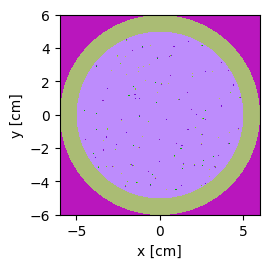

In [ ]:
#@title Plot
# colors = {
#     m_low: 'cornflowerblue',
#     m_coolant: 'blue',
#     m_HT9: 'darkslategray',
#     m_B4C: 'lawngreen',
#     m_B4C_e: 'darkgreen',
#     m_Plenum: 'red',
#     m_IC11: 'yellow',
#     m_IC12: 'yellow',
#     m_IC13: 'yellow',
#     m_IC14: 'yellow',
#     m_IC15: 'yellow',
#     m_IC21: 'olive',
#     m_IC22: 'olive',
#     m_IC23: 'olive',
#     m_IC24: 'olive',
#     m_IC25: 'olive'
# }
# colors = {
#     fuel: 'red',
#     PyC1: 'green',
#     PyC2: 'blue',
#     SiC: 'black',
#     graphite: 'darkslategray',
#     helium: 'purple'
# }
geometry.root_universe.plot(color_by='cell', origin=(0,0,0), width=(12,12),
                            basis='xy')

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

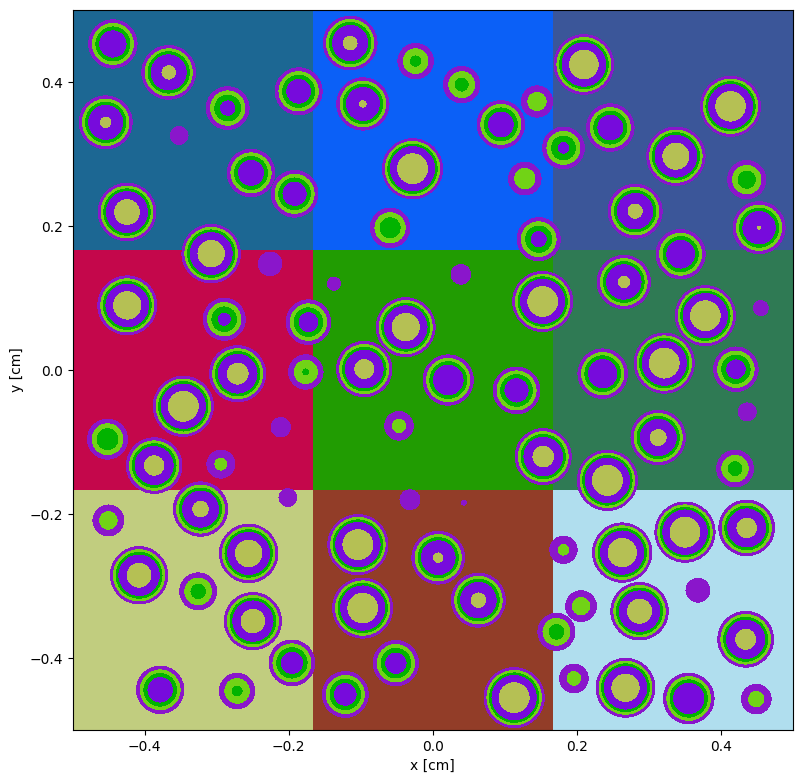

In [ ]:
geometry.plot(width=(1,1),basis='xy', pixels=(720,720), origin=(0,0,0.4)
              # , legend=True,
              # color_by='material'
              # colors = {
              # moderator: 'blue',
              # fuel1: 'olive',
              # fuel2: 'yellow',
              # cladding: 'purple'
              # }
)

In [ ]:
p = openmc.Plot.from_geometry(geometry)
p.color_by = 'material'
p.basis = 'yz'
p.origin = (0,0,240.1)
p.width = (180*2,481)
p.colors = colors
p.legend = True
p.pixels = (8000,8000)
p.show_overlaps = True
# p.overlap_color =('snow',)
p.to_ipython_image()